# 02 · Two-stage anchor-based detector: Faster R-CNN

Fixed protocol (`vdet.PROTOCOL`): train on folds ≠ 0 with every `step`-th frame, evaluate on fold 0 with every `val_step`-th frame, same input size, epochs and evaluator for every detector in this project.

Experiments (incremental): **E0** baseline → **E1** more RPN proposals → **E2** GIoU box-regression loss (on top of the better of E0/E1). Optional: **E3** RoI sampling, **E4** cosine schedule.

Sections: 1 setup · 2 protocol · 3 experiments · 4 results · 5 learning curves · 6 what each stage contributes · 7 failure analysis · 8 test submission.

## 1. Setup

In [1]:
import os, sys, json, shutil
from pathlib import Path

REPO = Path("/kaggle/working/repo") if Path("/kaggle").exists() else Path("..").resolve()
if Path("/kaggle").exists() and not REPO.exists():
    !git clone https://github.com/dd8ria/ai-hw2.git {REPO}
    !pip install -q faster-coco-eval
sys.path.insert(0, str(REPO / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as patches, cv2, torch
import vdet, tvdet
from vdet import CLASSES

vdet.seed_everything()
ROOT = vdet.find_data_root()
OUT = Path("/kaggle/working") if Path("/kaggle").exists() else REPO / "outputs"
RUNS = OUT / "runs"; RUNS.mkdir(parents=True, exist_ok=True)
print("device:", tvdet.DEVICE, torch.cuda.get_device_name() if torch.cuda.is_available() else "")

Cloning into '/kaggle/working/repo'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 50 (delta 11), reused 23 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 4.38 MiB | 9.18 MiB/s, done.
Resolving deltas: 100% (11/11), done.
device: cuda Tesla T4


In [2]:
# Kaggle sessions are capped, so runs are spread over several sessions. Attach the output
# of the previous notebook version as an input and its finished runs are copied back here.
for src in Path("/kaggle/input").glob("*/runs/*") if Path("/kaggle/input").exists() else []:
    if (src / "config.json").exists() and not (RUNS / src.name).exists():
        shutil.copytree(src, RUNS / src.name); print("restored", src.name)

## 2. Protocol and data

In [3]:
P = vdet.PROTOCOL
imgs, anns = vdet.load_all(ROOT)
folds = pd.read_csv(OUT / "folds.csv") if (OUT / "folds.csv").exists() else vdet.make_folds(imgs, P["n_folds"])
folds.to_csv(OUT / "folds.csv", index=False)   # the parallel runner reads the split from this file
train_frames, val_frames = vdet.protocol_frames(imgs, folds, P)
print(json.dumps(P))
print(f"train: {len(train_frames)} frames / {train_frames.clip_uid.nunique()} clips | "
      f"val: {len(val_frames)} frames / {val_frames.clip_uid.nunique()} clips")

{"val_fold": 0, "n_folds": 5, "step": 10, "val_step": 10, "imgsz": 1280, "epochs": 12, "seed": 42}
train: 2189 frames / 51 clips | val: 545 frames / 12 clips


**Training setup.** torchvision `fasterrcnn_resnet50_fpn_v2` with COCO-pretrained weights; the 91-class box predictor is replaced by a 9-way one (8 classes + background). Every image is resized so its long side equals `imgsz` (`min_size = max_size = imgsz`), then ImageNet-normalised inside the model. Augmentation: horizontal flip p = 0.5; ignored regions grey-filled in training images (as in notebook 01). SGD, momentum 0.9, weight decay 1e-4, batch 4, lr 0.01 (linear scaling of 0.02 @ batch 16), 500-iteration linear warm-up, ×0.1 decay at 67 % and 89 % of training, mixed precision, gradient clipping at 10. At inference: score threshold 0.01, up to 500 detections per image. Reported numbers come from the **last** epoch, not the best one, so the holdout is not used for model selection.

## 3. Experiments

In [4]:
BASE = dict(arch="fasterrcnn_v2", imgsz=P["imgsz"], epochs=P["epochs"], batch=4, lr=0.01,
            sched="step", box_loss="smooth_l1", seed=P["seed"])

# E1: dense scenes have hundreds of objects but torchvision keeps only 1000 proposals at test time
MORE_PROPOSALS = dict(rpn_pre_nms_top_n_train=4000, rpn_post_nms_top_n_train=3000,
                      rpn_pre_nms_top_n_test=4000, rpn_post_nms_top_n_test=3000)

# E2 is applied on top of whichever of E0/E1 wins -- set after E1 finishes
GIOU_ON = "frcnn_e1_proposals"

EXPERIMENTS = {
    "frcnn_e0_base": BASE,
    "frcnn_e1_proposals": {**BASE, "kwargs": MORE_PROPOSALS},
}
EXPERIMENTS["frcnn_e2_giou"] = {**EXPERIMENTS[GIOU_ON], "box_loss": "giou", "box_loss_weight": 10.0}
# optional extras
EXPERIMENTS["frcnn_e3_roi_sampling"] = {**EXPERIMENTS[GIOU_ON],
    "kwargs": {**EXPERIMENTS[GIOU_ON].get("kwargs", {}), "box_batch_size_per_image": 1024, "box_positive_fraction": 0.5}}
EXPERIMENTS["frcnn_e4_cosine"] = {**EXPERIMENTS["frcnn_e2_giou"], "sched": "cosine"}

iters = len(train_frames) // BASE["batch"] * BASE["epochs"]
print(f"{iters} iterations per run")
pd.DataFrame(EXPERIMENTS).T[["box_loss", "sched", "kwargs"]]

6564 iterations per run


,box_loss,sched,kwargs
frcnn_e0_base,smooth_l1,step,NaN
frcnn_e1_proposals,smooth_l1,step,"{'rpn_pre_nms_top_n_train': 4000, 'rpn_post_nm..."
frcnn_e2_giou,giou,step,"{'rpn_pre_nms_top_n_train': 4000, 'rpn_post_nm..."
frcnn_e3_roi_sampling,smooth_l1,step,"{'rpn_pre_nms_top_n_train': 4000, 'rpn_post_nm..."
frcnn_e4_cosine,giou,cosine,"{'rpn_pre_nms_top_n_train': 4000, 'rpn_post_nm..."


In [5]:
# Run one or two experiments per session; finished runs are skipped automatically.
# Accelerator "GPU T4 x2": two runs train at the same time, one per GPU (quota is per session hour).
# Queue as many runs as fit into the 12 h session; finished runs are skipped automatically.
# Logs: runs/<name>.log. With one GPU the queue simply runs one after another.
import parallel
RUN = ["frcnn_e0_base", "frcnn_e1_proposals", "frcnn_e2_giou", "frcnn_e3_roi_sampling", "frcnn_e4_cosine"]
codes = parallel.run_parallel([(n, EXPERIMENTS[n]) for n in RUN], RUNS, folds_csv=OUT / "folds.csv")

5 jobs on GPUs [0, 1]
[   0.0 min] started frcnn_e0_base on GPU 0
[   0.0 min] started frcnn_e1_proposals on GPU 1
[   0.5 min] frcnn_e0_base (GPU 0):   print(f"ep {ep} it {it}/{len(dl)} loss {float(loss):.3f} lr {opt.param_groups[0]['lr']:.5f}")
[   0.5 min] frcnn_e1_proposals (GPU 1):   print(f"ep {ep} it {it}/{len(dl)} loss {float(loss):.3f} lr {opt.param_groups[0]['lr']:.5f}")
[  10.5 min] frcnn_e0_base (GPU 0): epoch 1: AP 0.2177 AP50 0.4482 AP_s 0.1063 (6.6 min)
[  10.5 min] frcnn_e1_proposals (GPU 1): epoch 1: AP 0.2084 AP50 0.4348 AP_s 0.1003 (7.4 min)
[  20.5 min] frcnn_e0_base (GPU 0): epoch 2: AP 0.2297 AP50 0.4451 AP_s 0.0975 (6.6 min)
[  20.5 min] frcnn_e1_proposals (GPU 1): epoch 2: AP 0.2250 AP50 0.4450 AP_s 0.1069 (7.4 min)
[  30.5 min] frcnn_e0_base (GPU 0): epoch 4: AP 0.2303 AP50 0.4606 AP_s 0.0919 (6.6 min)
[  30.5 min] frcnn_e1_proposals (GPU 1): epoch 3: AP 0.2518 AP50 0.4815 AP_s 0.1145 (7.5 min)
[  40.5 min] frcnn_e0_base (GPU 0): epoch 5: AP 0.2460 AP50 0.4645 

## 4. Results

In [6]:
res = vdet.collect_results([RUNS, REPO / "results"], "frcnn")
cols = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_max", "ms_per_img", "fps", "best_epoch", "epochs"]
if len(res):
    res.to_csv(OUT / "results_frcnn.csv")
    display(res[[c for c in cols if c in res]].style.format("{:.4f}", subset=["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_max"]).format("{:.1f}", subset=["ms_per_img", "fps"]))
    display(res[[f"AP_{c}" for c in CLASSES]].style.format("{:.3f}").background_gradient(axis=None))

,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_max,ms_per_img,fps,best_epoch,epochs
run,,,,,,,,,,,
frcnn_e0_base,0.2492,0.4650,0.2320,0.1058,0.2101,0.4356,0.3700,64.7,15.5,9,12
frcnn_e1_proposals,0.2561,0.4795,0.2441,0.1094,0.2032,0.4448,0.3902,114.3,8.8,5,12
frcnn_e2_giou,0.2507,0.4721,0.2266,0.1106,0.2058,0.4357,0.3900,105.7,9.5,3,12
frcnn_e3_roi_sampling,0.2471,0.4575,0.2310,0.1119,0.2049,0.4277,0.3782,113.7,8.8,3,12
frcnn_e4_cosine,0.2427,0.4546,0.2260,0.1040,0.1989,0.4334,0.3845,107.2,9.3,5,12


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
run,,,,,,,,
frcnn_e0_base,0.197,0.044,0.490,0.268,0.074,0.276,0.517,0.127
frcnn_e1_proposals,0.203,0.038,0.497,0.260,0.151,0.278,0.490,0.131
frcnn_e2_giou,0.206,0.039,0.496,0.265,0.135,0.264,0.478,0.124
frcnn_e3_roi_sampling,0.206,0.038,0.489,0.257,0.091,0.292,0.476,0.126
frcnn_e4_cosine,0.198,0.038,0.485,0.252,0.113,0.277,0.460,0.118


Read the table incrementally: each row differs from the previous one by a single change. A gap between `best_epoch` and `epochs` signals over-fitting or an LR schedule that decays too late.

## 5. Learning curves

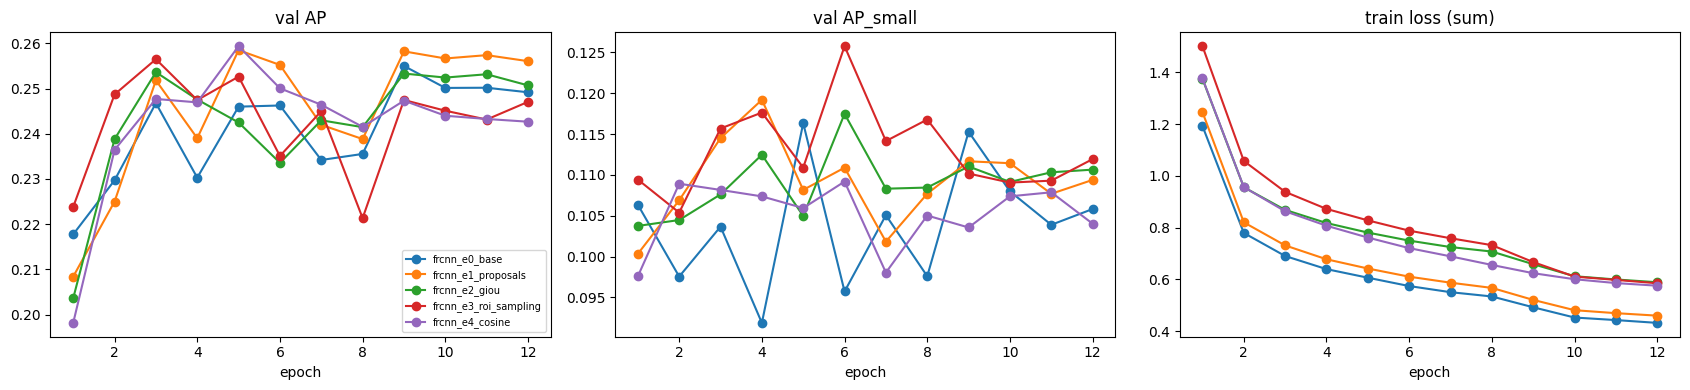

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for d in sorted(RUNS.glob("frcnn*")):
    if not (d / "history.json").exists(): continue
    h = pd.DataFrame(json.loads((d / "history.json").read_text()))
    axes[0].plot(h.epoch, h.AP, "o-", label=d.name); axes[1].plot(h.epoch, h.AP_small, "o-", label=d.name)
    loss_cols = [c for c in h if c.startswith("loss")]
    axes[2].plot(h.epoch, h[loss_cols].sum(axis=1), "o-", label=d.name)
for ax, t in zip(axes, ["val AP", "val AP_small", "train loss (sum)"]):
    ax.set_title(t); ax.set_xlabel("epoch")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(OUT / "frcnn_curves.png", dpi=120); plt.show()

## 6. What the two stages contribute

The **RPN** is a class-agnostic objectness detector on anchors: its job is recall (put at least one proposal on every object). The **second stage** pools features for each proposal (RoIAlign), classifies it into 8 classes + background and refines the box. Below we measure both on the holdout: proposal recall per object size (stage 1) versus recall and localisation quality of the final detections (stage 2).

In [8]:
ANALYSE = "frcnn_e1_proposals"
model = tvdet.load_run(RUNS / ANALYSE)
sub = val_frames.sample(min(150, len(val_frames)), random_state=0)
props = tvdet.rpn_proposals(model, sub)
dets = tvdet.predict(model, sub)
gt_sub = anns[anns.key.isin(sub.key) & (anns.iscrowd == 0)].copy()
gt_sub["bucket"] = pd.cut(gt_sub.w * gt_sub.h, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])

def best_iou(boxes, gts):
    out = np.zeros(len(gts)); p_by = dict(tuple(boxes.groupby("key")))
    for k, g in gts.groupby("key"):
        b = p_by.get(k)
        if b is not None and len(b):
            out[gts.index.get_indexer(g.index)] = vdet._iou_matrix(g[["x","y","w","h"]].values, b[["x","y","w","h"]].values).max(1)
    return out

rows = {}
for n in [100, 300, 1000, 3000]:
    rows[f"RPN top-{n}"] = best_iou(props[props["rank"] < n], gt_sub)
for thr in [0.05, 0.3]:
    rows[f"final dets, score≥{thr}"] = best_iou(dets[dets.score >= thr], gt_sub)
tab = pd.DataFrame({name: pd.Series(v, index=gt_sub.index).groupby(gt_sub.bucket, observed=False).apply(lambda s: (s >= 0.5).mean())
                    for name, v in rows.items()}).T
tab["mean best IoU"] = [np.mean(v) for v in rows.values()]
display(tab.style.format("{:.3f}").set_caption("recall at IoU≥0.5 by size, and mean IoU of the best-matching box"))
print("proposals per image:", props.groupby("key").size().median())

bucket,small,medium,large,mean best IoU
RPN top-100,0.353,0.674,0.920,0.535
RPN top-300,0.493,0.805,0.966,0.632
RPN top-1000,0.612,0.884,0.982,0.692
RPN top-3000,0.621,0.901,0.999,0.705
"final dets, score≥0.05",0.435,0.794,0.968,0.613
"final dets, score≥0.3",0.358,0.734,0.951,0.571


proposals per image: 3000.0


Interpretation guide: if RPN top-1000 recall on *small* objects is already low, no second-stage change can recover them (fix anchors / resolution / more proposals). If proposal recall is high but final recall is much lower, the losses happen in classification/NMS (second stage). Higher mean IoU for final detections than for proposals quantifies the box refinement of stage 2.

## 7. Failure analysis

detections with score ≥ 0.3:
type
tp              0.550
ignored         0.184
background      0.117
class           0.072
localization    0.070
duplicate       0.006


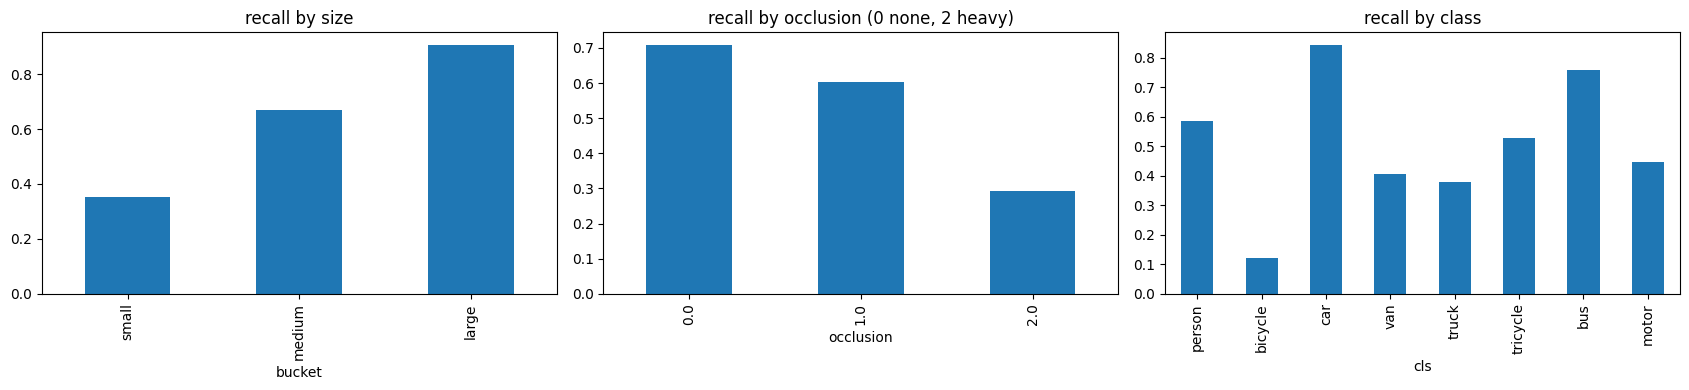

cls,bicycle,bus,car,motor,person,tricycle,truck,van
gt_cls,,,,,,,,
bicycle,0,0,0,365,204,15,0,0
bus,0,0,3,0,0,0,12,8
car,0,2,0,0,0,6,36,203
motor,265,0,9,0,189,32,1,0
person,17,0,3,93,0,5,0,0
tricycle,20,0,39,144,27,0,38,9
truck,0,10,41,0,0,31,0,26
van,0,4,330,0,0,13,22,0


In [9]:
preds = pd.read_csv(RUNS / ANALYSE / "val_preds.csv.gz")
SCORE_THR = 0.3
det_err, gt_err = vdet.error_breakdown(anns, preds, val_frames.key, score_thr=SCORE_THR)
print(f"detections with score ≥ {SCORE_THR}:"); print(det_err.type.value_counts(normalize=True).round(3).to_string())
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
gt_err.groupby("bucket", observed=False).matched.mean().plot.bar(ax=axes[0], title="recall by size")
if "occlusion" in gt_err:
    gt_err.groupby("occlusion").matched.mean().plot.bar(ax=axes[1], title="recall by occlusion (0 none, 2 heavy)")
gt_err.groupby(gt_err.cls.map(dict(enumerate(CLASSES)))).matched.mean().reindex(CLASSES).plot.bar(ax=axes[2], title="recall by class")
plt.tight_layout(); plt.show()

conf = det_err[det_err.type == "class"]
if len(conf):
    cm = pd.crosstab(conf.gt_cls.map(dict(enumerate(CLASSES))), conf.cls.map(dict(enumerate(CLASSES))))
    display(cm.style.background_gradient(axis=None).set_caption("class confusions: rows = true class, cols = predicted"))

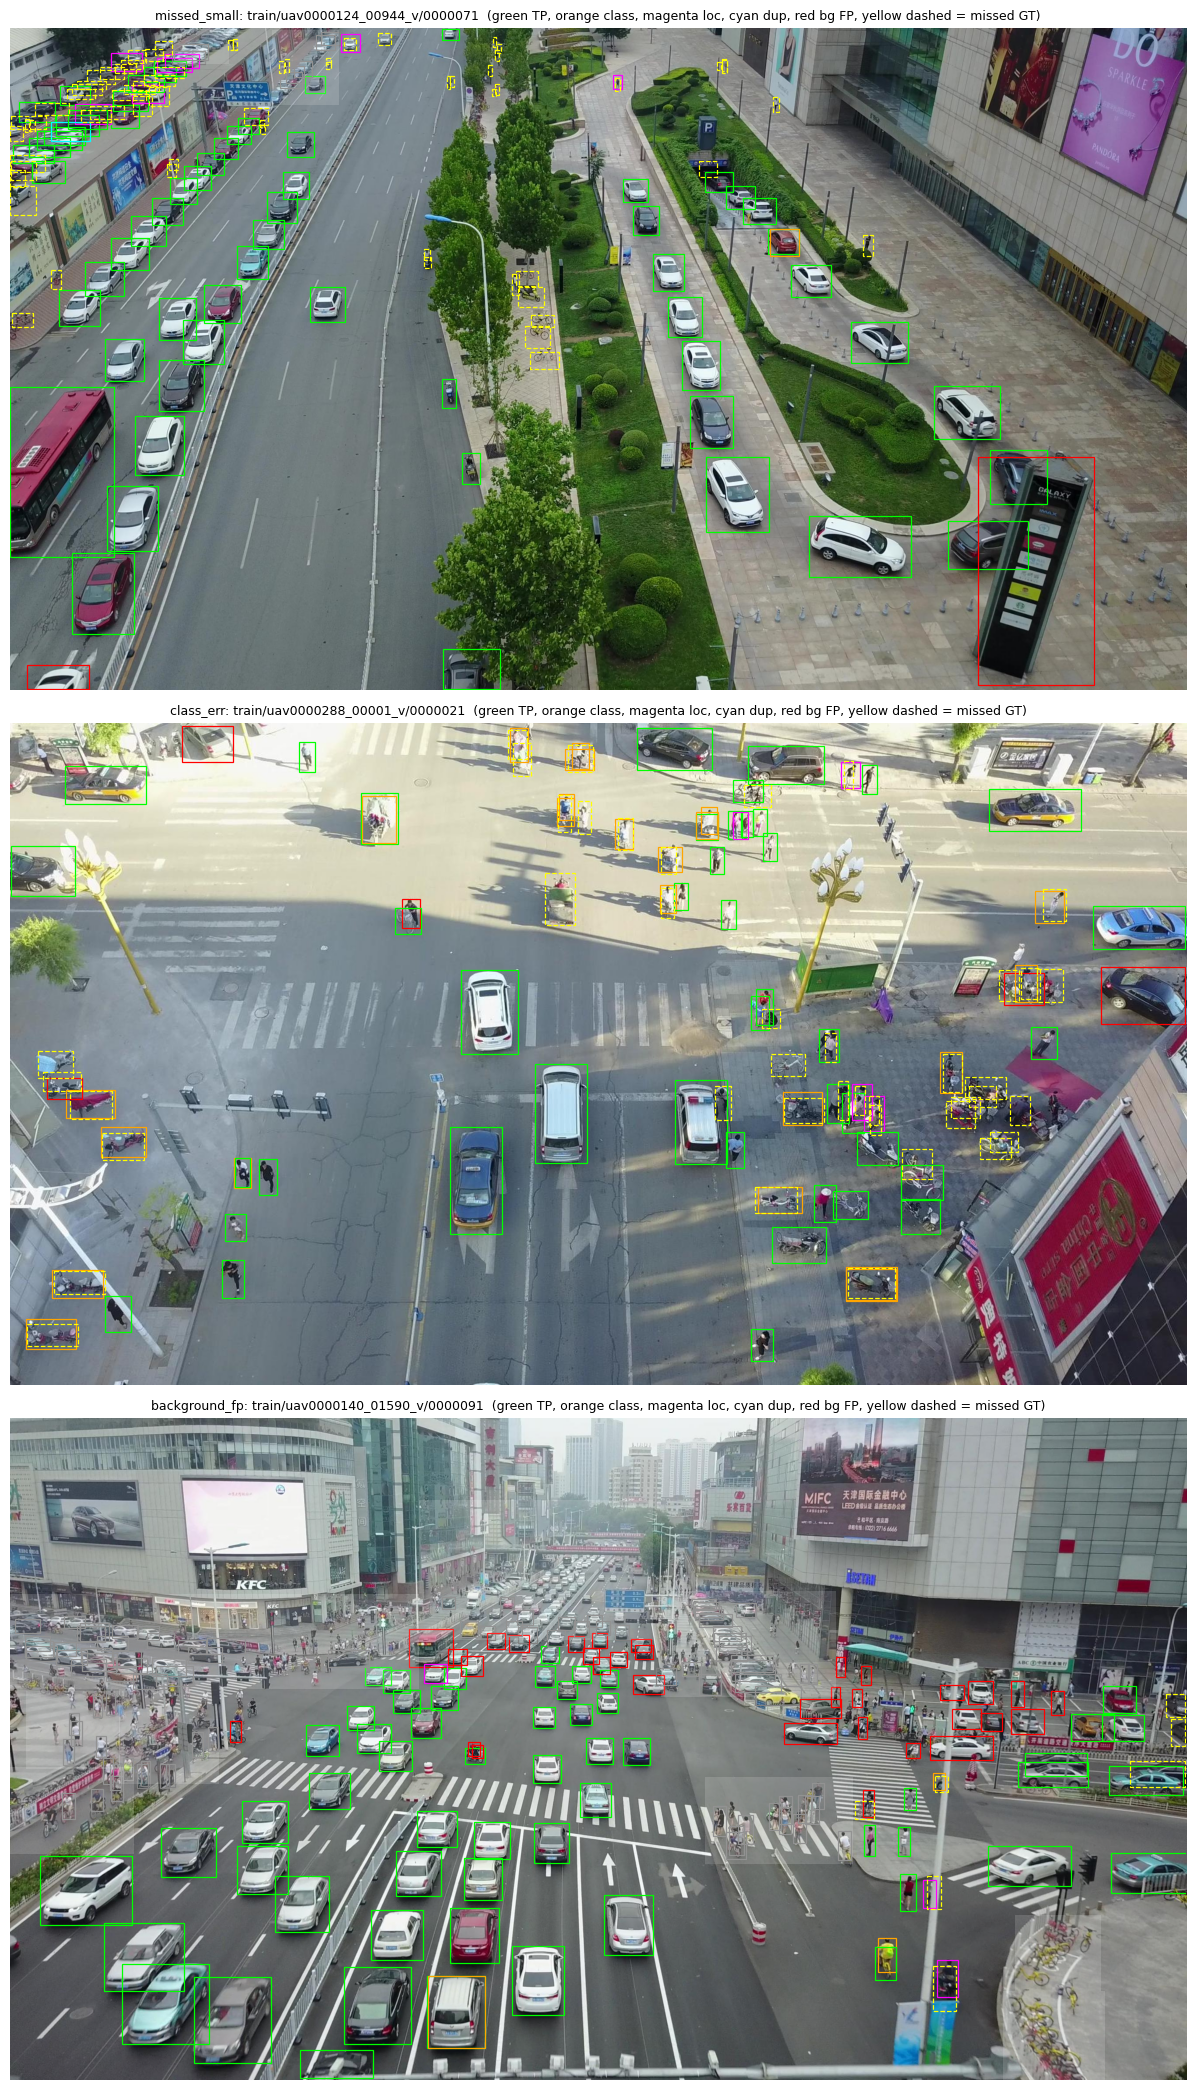

In [10]:
COL = {"tp": "lime", "class": "orange", "localization": "magenta", "duplicate": "cyan", "background": "red", "ignored": "grey"}

def show_errors(key, ax, title):
    r = next(imgs[imgs.key == key].itertuples())
    ax.imshow(cv2.cvtColor(cv2.imread(r.img_path), cv2.COLOR_BGR2RGB))
    for b in det_err[det_err.key == key].itertuples():
        ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False, lw=0.9, ec=COL[b.type]))
    for b in gt_err[(gt_err.key == key) & ~gt_err.matched].itertuples():
        ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False, lw=0.9, ec="yellow", ls="--"))
    for b in anns[(anns.key == key) & (anns.iscrowd == 1)].itertuples():
        ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=True, alpha=0.15, fc="white"))
    ax.set_title(title, fontsize=9); ax.axis("off")

per_frame = pd.DataFrame({
    "missed_small": gt_err[~gt_err.matched & (gt_err.bucket == "small")].groupby("key").size(),
    "class_err": det_err[det_err.type == "class"].groupby("key").size(),
    "background_fp": det_err[det_err.type == "background"].groupby("key").size(),
}).fillna(0)
cases = {c: per_frame[c].idxmax() for c in per_frame}
fig, axes = plt.subplots(len(cases), 1, figsize=(14, 7 * len(cases)))
for ax, (c, k) in zip(np.atleast_1d(axes), cases.items()):
    show_errors(k, ax, f"{c}: {k}  (green TP, orange class, magenta loc, cyan dup, red bg FP, yellow dashed = missed GT)")
plt.tight_layout(); plt.savefig(OUT / "frcnn_failures.png", dpi=110); plt.show()

Describe each case with a plausible cause (fill after looking at the figures), e.g.:

1. **Missed small objects** — people/motors under ~10 px after resize fall below one P2/P3 cell and below the smallest default anchor (32 px); RPN recall in Section 6 confirms whether proposals exist at all.
2. **Class confusion** — car ↔ van and bicycle ↔ motor look alike from above at this scale; the confusion matrix shows which pairs dominate.
3. **Background false positives** — repetitive textures (roof parts, road markings) or un-annotated objects next to ignored regions; check whether red boxes sit near the white (ignored) areas.

## 8. Test predictions and submission

In [11]:
SUBMIT = "frcnn_e1_proposals"
model = tvdet.load_run(RUNS / SUBMIT)
test_preds = tvdet.predict_test(model, ROOT)
test_preds.to_csv(OUT / f"test_preds_{SUBMIT}.csv.gz", index=False)
sub = vdet.write_submission(test_preds, ROOT / "test_images.csv", OUT / f"submission_{SUBMIT}.csv")
print("mean detections per image:", round(test_preds.groupby("image_id").size().mean(), 1))

submission OK: 3811 rows, 3811 non-empty
mean detections per image: 172.7


In [12]:
# Results for the repo: unzip results.zip from the notebook Output into <repo>/results/ and commit.
vdet.export_results(RUNS, OUT / "results", preds_for=(SUBMIT,))

results archive: /kaggle/working/results.zip


PosixPath('/kaggle/working/results.zip')